# Delivery 1 — Follow-up #1: Obtain, Scrub & Explore
### Predicting Formula 1 Points Finishes (2010–2024): A Temporal Study of Qualifying Position, Rolling Constructor Momentum, and Historical Circuit Affinity

* **Course:** Fundamentals of Machine Learning (2026–27) — Autonomous University of Barcelona (UAB)
* **Project Team 05:** Marc Font Hostalet, David Redrejo Pérez, Elias Barreiro Pena
* **Workflow Scope (OSEMN — Follow-up #1, Dec 4):** **Obtain** $\rightarrow$ **Scrub** $\rightarrow$ **Temporal Feature Engineering** $\rightarrow$ **Zero-Leakage Verification** $\rightarrow$ **Explore (EDA)**
* **Dataset:** Formula 1 World Championship (1950–2024), Ergast / Kaggle relational tables (`rohanrao/formula-1-world-championship-1950-2020`)

---

## 1. Research Objective, Hypothesis & Methodological Guardrails

**Objective:** Predict whether a driver finishes in the points (**Top-10**, binary classification) in the modern Formula 1 points-scoring era (**2010–2024**) using strictly **pre-race** information organized into three disjoint factor groups:
1. **Group A (`A_qualifying`, 8 features):** Starting grid & Saturday qualifying pace/context.
2. **Group B (`B_form`, 11 features):** Strictly prior-race rolling constructor and driver momentum & reliability.
3. **Group C (`C_track`, 7 features):** Circuit structural properties and strictly prior historical driver/constructor circuit affinity.

**Research Hypothesis:** Qualifying rank and recent constructor/driver rolling momentum carry substantially greater predictive weight than historical circuit affinity, enabling interpretable regularized linear models (Regularized Logistic Regression & Linear SVM) to match or exceed non-linear tree ensembles while outperforming the strong `grid <= 10` heuristic baseline (~77% accuracy).

### Explicit Alignment with Instructor Feedback
| Instructor Requirement | Implemented Engineering Guardrail |
| :--- | :--- |
| **Restrict period (scoring rules changed)** | Target modeling rows strictly restricted to **2010–2024** (unified Top-10 points regime, **47.4%** positive rate). Pre-2010 data (1995–2009) used *only* for warm-starting strictly past historical counts/averages. |
| **Never use in-race variables as features** | Zero columns from `lap_times`, `pit_stops`, target-race `status`, race `laps`/`time`/`milliseconds`, `fastestLap`, or post-race standings enter the feature matrix. Enforced via `FORBIDDEN_INRACE_COLUMNS` schema assertions. |
| **Compute rolling features strictly from prior races** | All rolling & historical statistics are aggregated to race level and shifted strictly by 1 race (preventing both same-race target leakage and same-race teammate leakage). Verified by automated adversarial mutation tests. |
| **Split strictly by season** | **Development:** 2010–2021 (12 seasons, $n=5{,}077$, 5-fold expanding-window CV on 2017–2021). **Held-out Test:** 2022–2024 Ground-Effect era (3 seasons, $n=1{,}359$). All exploratory feature-target analyses are restricted to 2010–2021. |
| **Establish `grid <= 10` (~77%) baseline** | Evaluated both raw (`76.03%`) and scrubbed (`76.91%`, fixing `grid == 0` pit-lane starts) across all seasons and in the high-uncertainty midfield zone (P8–P13). |
| **Prepare 3-group ablation study** | Features cleanly partitioned into disjoint Groups A, B, and C for the full $2^3 - 1 = 7$-subset ablation matrix in Follow-up #2. |

In [1]:
# Standard imports and project path setup
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.data import (
    CONSTRUCTOR_LINEAGE_MAP,
    FORBIDDEN_INRACE_COLUMNS,
    load_raw_tables,
    run_obtain_and_scrub,
)
from src.features import (
    ALL_FEATURES,
    CV_VAL_SEASONS,
    FEATURE_GROUPS,
    FEATURE_LABELS,
    TEST_START_YEAR,
    TRAIN_END_YEAR,
    build_feature_dataset,
    get_temporal_splits,
    save_processed_dataset,
    verify_no_leakage,
)
from src.eda import run_followup1_eda
from src.utils import DATA_PROCESSED_DIR, FIGURES_F1_DIR, REPORTS_DIR, ensure_directories

ensure_directories()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\david\OneDrive\AI UAB\MACHINE LEARNING\project


---
## 2. Obtain — Relational Schema Audit & Scoring Era Selection

The Ergast / Kaggle Formula 1 dataset is a **normalized relational database** comprising 14 CSV tables linked via foreign keys (`raceId`, `driverId`, `constructorId`, `circuitId`, `statusId`). Below we audit all loaded tables, verify complete 1950–2024 coverage, and empirically motivate restricting our modeling target to **2010–2024**.

In [2]:
# Load all core relational tables and execute Obtain + Scrub audit
tables = load_raw_tables()
base_df, audit = run_obtain_and_scrub(save_audit=True)

# 1) Relational table summary
table_audit_df = (
    pd.DataFrame.from_dict(audit["raw_tables"], orient="index")
    .reset_index()
    .rename(columns={"index": "table_name"})
    .sort_values("rows", ascending=False)
    .reset_index(drop=True)
)
display(table_audit_df)

# 2) Historical FIA scoring rule regimes (1950-2024)
eras_df = pd.DataFrame(audit["scoring_eras"])
eras_df["points_scoring_rate"] = (eras_df["points_scoring_rate"] * 100).round(2)
eras_df["top10_rate"] = (eras_df["top10_rate"] * 100).round(2)
eras_df["mean_field_size"] = eras_df["mean_field_size"].round(1)
print("\nHistorical FIA Scoring Regimes (Justifying 2010-2024 Period Restriction):")
display(eras_df)

2026-11-19 16:00:40 | INFO | f1_ml.data | All required raw CSV tables already exist in C:\Users\david\OneDrive\AI UAB\MACHINE LEARNING\project\data\raw


2026-11-19 16:00:43 | INFO | f1_ml.data | Built scrubbed base table (1995-2024): 11914 rows across 561 races (2010+: 6436 rows, 305 races)


,table_name,rows,cols,missing_cells
0,driver_standings,34863,7,0
1,results,26759,18,122887
2,constructor_standings,13391,7,0
3,constructor_results,12625,5,12608
4,qualifying,10494,9,11668
5,races,1125,18,11349
6,drivers,861,9,1559
7,sprint_results,360,16,73
8,constructors,212,5,0
9,status,139,2,0



Historical FIA Scoring Regimes (Justifying 2010-2024 Period Restriction):


,era,rows,races,points_scoring_rate,top10_rate,mean_field_size
0,1950-1959 (Top 5),2007,84,23.62,45.34,23.9
1,1960-2002 (Top 6),15782,613,23.22,38.85,25.7
2,2003-2009 (Top 8),2534,123,38.75,48.54,20.6
3,2010-2024 (Top 10),6436,305,47.39,47.39,21.1


**Key Obtain Findings:**
* Prior to 2010, FIA points were awarded only to the Top 5 (1950–59), Top 6 (1960–2002), or Top 8 (2003–09), creating severe target imbalance (23%–39% points rate) and shifting team strategic incentives.
* Since **2010**, FIA awards championship points to the **Top 10** finishers (`25-18-15-12-10-8-6-4-2-1`). Across **2010–2024** (**305 Grands Prix**, **6,436 driver-race entries**), `positionOrder <= 10`, `position <= 10`, and `points > 0` agree with **0 discrepancies**, yielding a nearly balanced **47.39%** positive target rate.

---
## 3. Scrub — Real-World Formula 1 Data Anomalies & Domain Fixes

Raw motorsport telemetry and archival tables contain subtle data-quality traps that silently corrupt naive pipelines. Our scrubbing module (`src/data.py`) resolves four critical domain anomalies:

1. **Ergast Null Tokens (`\N`):** Explicitly decoded as `NaN` across all tables at ingestion time.
2. **Pit-Lane Starts Encoded as `grid == 0` (85 entries in 2010–2024):** In Ergast, drivers starting from the pit lane (or failing to take the grid) are stored with `grid = 0`. A naive `grid <= 10` rule falsely treats pit-lane starters as **pole position** (`0 <= 10`), depressing baseline accuracy to `76.03%`. Mapping `grid == 0` to back-of-grid (`n_entries + 1`) plus an explicit pre-race flag `is_pit_lane_start` lifts the baseline by **+0.89 percentage points** to **76.91%**.
3. **Constructor Rebrands Breaking Longitudinal Form Continuity:** Ergast assigns new `constructorId`s across team rebrands—and even **reverted Kick Sauber in 2024 back to ID 15 (2018 Sauber)** after 5 seasons as Alfa Romeo (ID 51)! Without lineage canonicalization (`CONSTRUCTOR_LINEAGE_MAP`), 2024 Round 1 Sauber rolling form would jump back to 2018 data, and AlphaTauri $\rightarrow$ RB or Force India $\rightarrow$ Racing Point $\rightarrow$ Aston Martin would reset to cold-start histories.
4. **Missing Qualifying Records (24 rows) & Missing Q1 Times (86 rows):** Occur when a driver crashes in practice or is excluded from qualifying and starts at the back. `qualy_pos` falls back to scrubbed `grid_clean`, while missing `qualy_gap_to_pole_pct` remains `NaN` for **strictly within-fold median imputation** inside scikit-learn pipelines (zero global imputation leakage).

In [3]:
# Inspect scrubbing diagnostics quantitatively
scrub = audit["scrubbing_findings"]
print("=== Scrubbing Audit Summary (2010-2024) ===")
print(f"Modeling rows / races              : {audit['modeling_rows']:,} entries across {audit['modeling_races']} Grands Prix")
print(f"Unique drivers / circuits          : {audit['modeling_drivers']} drivers, {audit['modeling_circuits']} circuits")
print(f"Constructors raw -> lineages       : {audit['modeling_constructors_raw']} raw IDs -> {audit['modeling_constructor_lineages']} canonical lineages")
print(f"Target positive rate (top10)       : {audit['target_positive_rate']*100:.2f}% (discrepancies vs points>0: {audit['target_discrepancy_posOrder_vs_points']})")
print(f"Pit-lane/grid==0 entries           : {scrub['grid_zero_entries']} (of which {scrub['grid_zero_top10_finishes']} recovered to Top-10)")
print(f"Missing qualifying rows / Q1 times : {scrub['missing_qualifying_rows']} rows / {scrub['missing_best_q_ms']} lap times")
print(f"Naive raw grid <= 10 accuracy      : {scrub['raw_grid_le_10_accuracy']*100:.2f}%")
print(f"Scrubbed grid_clean <= 10 accuracy : {scrub['scrubbed_grid_le_10_accuracy']*100:.2f}% (+{scrub['scrubbing_baseline_gain_pp']:.2f} pp)")

# Season-by-season table (2010-2024)
season_df = pd.DataFrame(audit["season_summary"])
season_df["top10_rate"] = (season_df["top10_rate"] * 100).round(1)
season_df["dnf_rate"] = (season_df["dnf_rate"] * 100).round(1)
season_df["grid10_clean_acc"] = (season_df["grid10_clean_acc"] * 100).round(2)
season_df["mean_field_size"] = season_df["mean_field_size"].round(1)
season_df["temporal_split"] = np.where(
    season_df["year"] <= 2016,
    "Train Core",
    np.where(season_df["year"] <= TRAIN_END_YEAR, "Train / Expanding CV Val", "Held-Out Test (Ground-Effect)"),
)
display(season_df)

=== Scrubbing Audit Summary (2010-2024) ===
Modeling rows / races              : 6,436 entries across 305 Grands Prix
Unique drivers / circuits          : 80 drivers, 35 circuits
Constructors raw -> lineages       : 23 raw IDs -> 13 canonical lineages
Target positive rate (top10)       : 47.39% (discrepancies vs points>0: 0)
Pit-lane/grid==0 entries           : 85 (of which 14 recovered to Top-10)
Missing qualifying rows / Q1 times : 24 rows / 86 lap times
Naive raw grid <= 10 accuracy      : 76.03%
Scrubbed grid_clean <= 10 accuracy : 76.91% (+0.89 pp)


,year,races,entries,mean_field_size,top10_rate,dnf_rate,pit_lane_starts,grid10_clean_acc,temporal_split
0,2010,19,456,24.0,41.7,25.9,0,77.19,Train Core
1,2011,19,456,24.0,41.7,18.0,3,78.95,Train Core
2,2012,20,480,24.0,41.7,19.0,3,73.33,Train Core
3,2013,19,418,22.0,45.5,15.3,0,81.34,Train Core
4,2014,19,407,21.4,46.7,21.1,0,77.40,Train Core
5,2015,19,378,19.9,50.3,21.4,3,75.13,Train Core
6,2016,21,462,22.0,45.5,18.2,4,82.03,Train Core
7,2017,20,400,20.0,50.0,23.8,2,74.75,Train / Expanding CV Val
8,2018,21,420,20.0,50.0,20.2,1,74.29,Train / Expanding CV Val
9,2019,21,420,20.0,50.0,14.3,12,74.29,Train / Expanding CV Val


---
## 4. Leakage-Free Temporal Feature Engineering (3 Factor Groups)

We engineer **26 strictly pre-race features** partitioned cleanly into three mutually exclusive factor groups (`src/features.py`):

* **Group A — Qualifying & Grid Context (8 features):** `grid_clean`, `grid_pct`, `is_pit_lane_start`, `qualy_pos`, `grid_penalty_drop` ($\max(0, \text{grid\_clean} - \text{qualy\_pos})$, non-linearly isolating grid penalties without exact algebraic rank deficiency), `reached_q3`, `qualy_gap_to_pole_pct` (scale-invariant qualifying deficit), and `qualy_delta_teammate_pct` (pure Saturday driver-vs-car delta).
* **Group B — Rolling Constructor & Driver Momentum (11 features):** All constructor streams are first aggregated to the **`(constructor_lineage, raceId)` race level** and shifted strictly by 1 race before rolling over $W \in \{3, 5, 10\}$ prior races so **neither car can see its teammate's outcome from the same race**. Points use the unified modern 25-18-...-1 scale (`modern_points_equiv`) for scale invariance across eras. Rates use **Empirical Bayes / MAP smoothing** $(\sum y + m \cdot p_0)/(n + m)$ with fixed domain priors (connecting directly to Lecture 5–6 Bayesian parameter estimation).
* **Group C — Historical Track & Circuit Characteristics (7 features):** Physical altitude (`circuit_alt_log`) plus strictly prior-race circuit dynamics (`circuit_hist_grid_corr` measuring overtaking difficulty, `circuit_hist_attrition_rate`, `circuit_hist_top10_retention`) and Empirical-Bayes-shrunk prior driver/constructor circuit affinity (`drv_circuit_hist_top10_rate`, `drv_circuit_prior_starts`, `const_circuit_hist_top10_rate`).

---
## 5. Automated Adversarial Zero-Leakage Audit

Rather than trusting shift logic by inspection alone, `verify_no_leakage()` runs **four automated adversarial invariants**:
1. **Schema Disjointness & Forbidden Column Audit:** Verifies zero overlap with `FORBIDDEN_INRACE_COLUMNS`.
2. **Future-Outcome Mutation Test:** Inverts *every* race outcome in 2022–2024 and asserts bit-for-bit identity (`max_abs_diff == 0.0`) across all 2010–2021 feature values.
3. **Same-Race & Teammate Mutation Test:** Inverts *every* driver & constructor outcome in a mid-season race (2023 Round 10, British GP) and asserts bit-for-bit identity (`max_abs_diff == 0.0`) for all 20 entries in that exact race and all prior races—while confirming the *next* race (`Round 11`) properly updates (`diff > 0`).
4. **Temporal Split Monotonicity:** Asserts $\max(\text{train.year}) < \min(\text{test.year})$ and strictly forward-chaining CV folds.

In [4]:
# Execute automated adversarial zero-leakage verification and persist processed dataset
leakage_report = verify_no_leakage(base_df, tables["results"], tables["races"])
mod_df = build_feature_dataset(base_df, tables["results"], tables["races"])
save_processed_dataset(mod_df, leakage_report)

print("=== AUTOMATED ZERO-LEAKAGE AUDIT REPORT ===")
for k, v in leakage_report.items():
    print(f"  {k:<38s}: {v}")

# Inspect engineered feature schema & exact missingness (all handled strictly inside CV pipelines)
schema_rows = []
for grp_name, cols in FEATURE_GROUPS.items():
    for col in cols:
        schema_rows.append(
            {
                "group": grp_name,
                "feature": col,
                "description": FEATURE_LABELS[col],
                "missing_total": int(mod_df[col].isna().sum()),
                "missing_pct": round(mod_df[col].isna().mean() * 100, 2),
                "mean_dev": round(float(mod_df.loc[mod_df["year"] <= TRAIN_END_YEAR, col].mean()), 3),
                "std_dev": round(float(mod_df.loc[mod_df["year"] <= TRAIN_END_YEAR, col].std()), 3),
            }
        )
display(pd.DataFrame(schema_rows))

2026-11-19 16:01:03 | INFO | f1_ml.features | Built modeling feature dataset (2010-2024): 6436 rows x 26 features (train_dev=5077, test=1359)


2026-11-19 16:01:13 | INFO | f1_ml.features | Built modeling feature dataset (2010-2024): 6436 rows x 26 features (train_dev=5077, test=1359)


2026-11-19 16:01:19 | INFO | f1_ml.features | Built modeling feature dataset (2010-2024): 6436 rows x 26 features (train_dev=5077, test=1359)


2026-11-19 16:01:19 | INFO | f1_ml.features | Leakage audit PASSED: {'status': 'PASSED', 'n_features_total': 26, 'group_counts': {'A_qualifying': 8, 'B_form': 11, 'C_track': 7}, 'forbidden_overlap_count': 0, 'future_mutation_max_abs_diff': 0.0, 'same_race_mutation_max_abs_diff': 0.0, 'next_race_rolling_sensitivity_diff': 5.833333333333334, 'train_years': [2010, 2021], 'test_years': [2022, 2024], 'cv_val_seasons': [2017, 2018, 2019, 2020, 2021], 'train_rows': 5077, 'test_rows': 1359}


2026-11-19 16:01:26 | INFO | f1_ml.features | Built modeling feature dataset (2010-2024): 6436 rows x 26 features (train_dev=5077, test=1359)


=== AUTOMATED ZERO-LEAKAGE AUDIT REPORT ===
  status                                : PASSED
  n_features_total                      : 26
  group_counts                          : {'A_qualifying': 8, 'B_form': 11, 'C_track': 7}
  forbidden_overlap_count               : 0
  future_mutation_max_abs_diff          : 0.0
  same_race_mutation_max_abs_diff       : 0.0
  next_race_rolling_sensitivity_diff    : 5.833333333333334
  train_years                           : [2010, 2021]
  test_years                            : [2022, 2024]
  cv_val_seasons                        : [2017, 2018, 2019, 2020, 2021]
  train_rows                            : 5077
  test_rows                             : 1359


,group,feature,description,missing_total,missing_pct,mean_dev,std_dev
0,A_qualifying,grid_clean,Starting Grid Position (scrubbed),0,0.00,11.306,6.322
1,A_qualifying,grid_pct,Normalized Grid Percentile,0,0.00,0.501,0.304
2,A_qualifying,is_pit_lane_start,Pit-Lane Start Indicator,0,0.00,0.009,0.094
3,A_qualifying,qualy_pos,Qualifying Rank,0,0.00,11.278,6.296
4,A_qualifying,grid_penalty_drop,Grid Penalty Drop (Places Lost),0,0.00,0.340,1.523
5,A_qualifying,reached_q3,Reached Q3 Shootout,0,0.00,0.449,0.497
6,A_qualifying,qualy_gap_to_pole_pct,Qualifying Gap to Pole (%),86,1.34,2.464,2.142
7,A_qualifying,qualy_delta_teammate_pct,Qualifying Gap vs Teammate (%),0,0.00,0.000,1.000
8,B_form,const_roll5_top10_rate,Constructor Top-10 Rate (Last 5),0,0.00,0.473,0.274
9,B_form,const_roll5_pts_per_car,Constructor Pts/Car (Last 5),8,0.12,4.719,5.325


---
## 6. Explore — Exploratory Data Analysis & Statistical Hypothesis Preview

To preserve complete scientific discipline, **all exploratory feature-target statistics, univariate ROC-AUC rankings, mutual information scores, VIF diagnostics, and circuit analyses are computed exclusively on the 2010–2021 Development split ($n=5{,}077$)**, keeping the 2022–2024 Ground-Effect Test set ($n=1{,}359$) untouched until Follow-up #2 evaluation.

In [5]:
# Run Follow-up #1 EDA statistics and generate all 6 publication-quality figures
eda_summary = run_followup1_eda(mod_df, audit, out_dir=FIGURES_F1_DIR)

# Display factor-group univariate summary table
grp_summary_df = pd.DataFrame(eda_summary["group_univariate_summary"])
print("=== Univariate Predictive Signal by Factor Group (Dev 2010-2021) ===")
display(grp_summary_df.round(4))

# Display full ranked feature statistics table
univar_df = pd.read_csv(REPORTS_DIR / "metrics" / "followup1_univariate_stats.csv")
print("\nTop 15 Pre-Race Features Ranked by Oriented Univariate ROC-AUC (Dev 2010-2021):")
display(
    univar_df[
        ["feature", "group", "univariate_auc", "direction", "mutual_info_nats", "spearman_r", "vif"]
    ]
    .head(15)
    .round(4)
)

2026-11-19 16:01:42 | INFO | f1_ml.eda | Follow-up #1 EDA complete. Saved 6 figures to C:\Users\david\OneDrive\AI UAB\MACHINE LEARNING\project\reports\figures\followup1


=== Univariate Predictive Signal by Factor Group (Dev 2010-2021) ===


,group,n_features,mean_auc,max_auc,mean_mi,max_mi,max_vif
0,A_qualifying,8,0.7088,0.8419,0.1180,0.2003,139.9391
1,B_form,11,0.7277,0.8346,0.1282,0.1990,22.1835
2,C_track,7,0.5765,0.7044,0.0288,0.0846,8.3575



Top 15 Pre-Race Features Ranked by Oriented Univariate ROC-AUC (Dev 2010-2021):


,feature,group,univariate_auc,direction,mutual_info_nats,spearman_r,vif
0,qualy_pos,A_qualifying,0.8419,-,0.1983,-0.5915,104.1167
1,grid_clean,A_qualifying,0.8362,-,0.2003,-0.5816,139.9391
2,const_season_pts_per_race,B_form,0.8346,+,0.1990,0.5798,16.6875
3,const_roll10_avg_pos,B_form,0.8326,-,0.1916,-0.5749,22.1835
4,const_roll5_pts_per_car,B_form,0.8326,+,0.1897,0.5764,19.5970
5,grid_pct,A_qualifying,0.8325,-,0.1869,-0.5747,53.5484
6,const_roll5_top10_rate,B_form,0.8222,+,0.1870,0.5600,13.8209
7,qualy_gap_to_pole_pct,A_qualifying,0.8200,-,0.1702,-0.5531,2.7596
8,drv_roll5_avg_pos,B_form,0.8109,-,0.1699,-0.5374,16.3539
9,drv_roll5_top10_rate,B_form,0.8009,+,0.1546,0.5273,12.2554


### Visual Story 1: Scoring Eras & Strict Season-Based Temporal Split

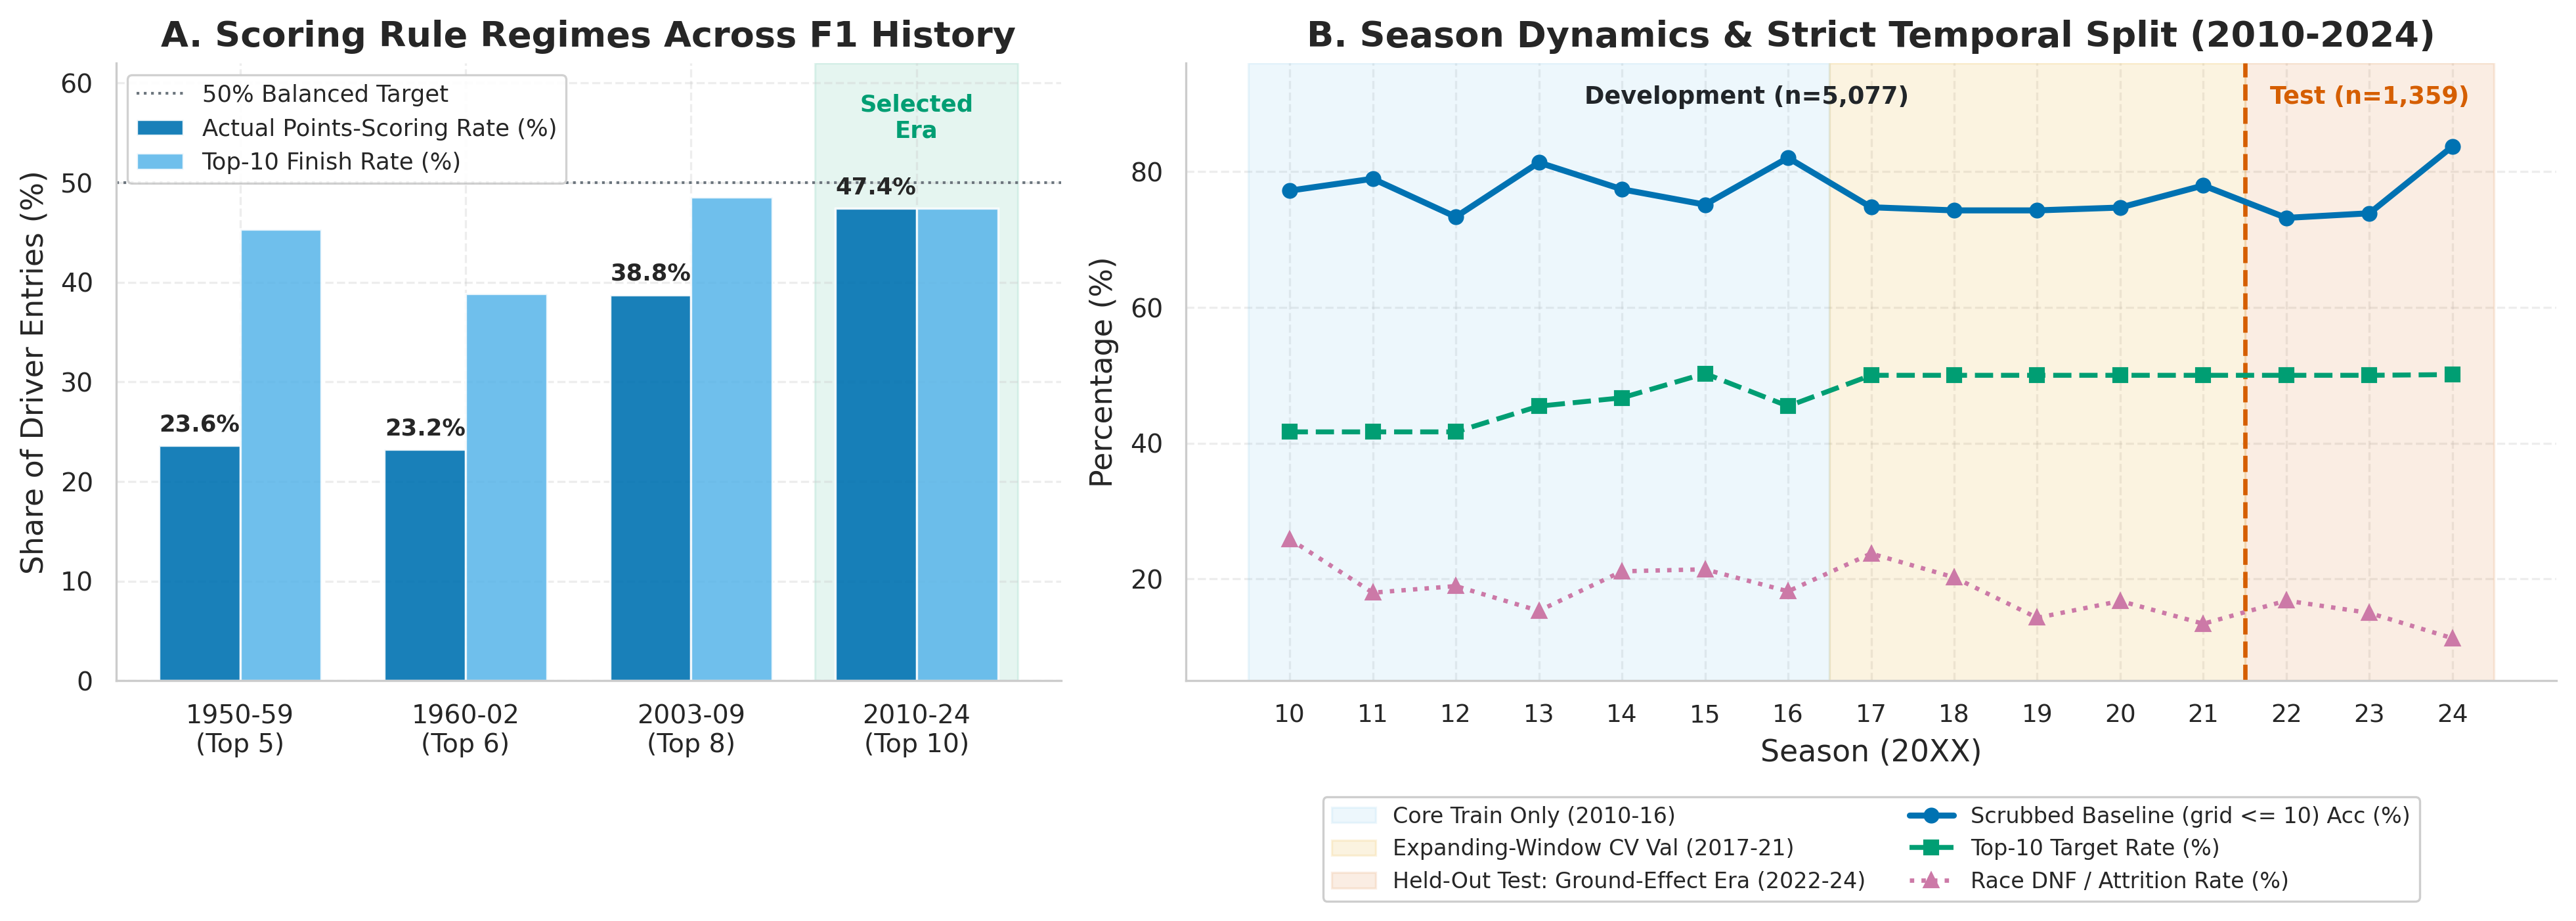

In [6]:
display(Image(filename=str(FIGURES_F1_DIR / "fig01_scoring_eras_and_temporal_split.png"), width=980))

### Visual Story 2: Grid Probability Curve, Pit-Lane Scrubbing & Midfield Failure Modes
Notice how the `grid <= 10` heuristic achieves **83.5%** outside the midfield, yet drops to **59.6%** inside the **P8–P13 midfield transition zone** (27.9% of all race entries). Moreover, Panel B proves that **Top-Tier teams starting P11+ still finish in the Top-10 55%–59% of the time**—directly violating the vertical `grid <= 10` decision rule!

Baseline grid <= 10 overall accuracy (Dev 2010-21) : 76.86%
  -> Outside P8-P13 (72.1% of grid)               : 83.55%
  -> Inside P8-P13 Midfield Zone (27.9% of grid)  : 59.59%


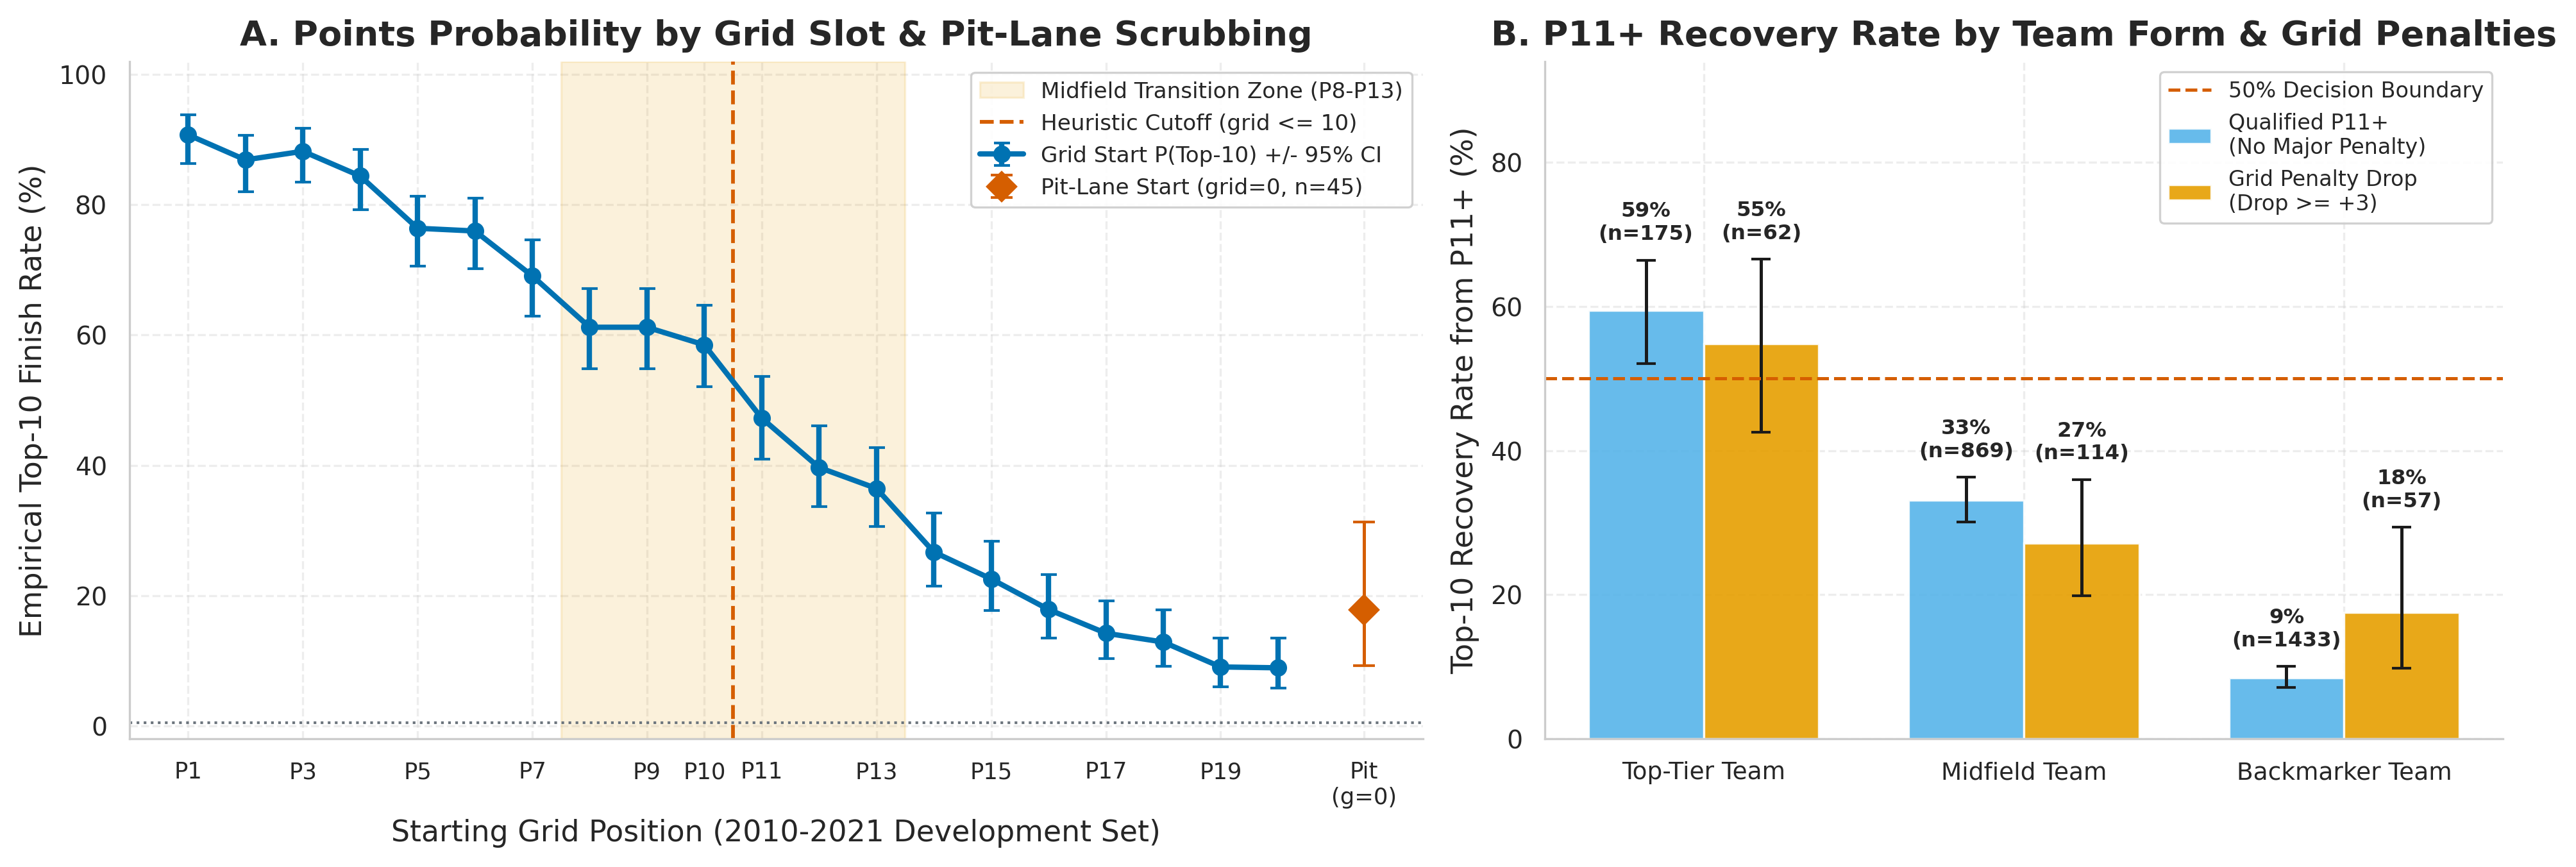

In [7]:
diag = eda_summary["baseline_grid10_diagnostics_train_dev"]
print(f"Baseline grid <= 10 overall accuracy (Dev 2010-21) : {diag['overall_acc']*100:.2f}%")
print(f"  -> Outside P8-P13 (72.1% of grid)               : {diag['outside_midfield_acc']*100:.2f}%")
print(f"  -> Inside P8-P13 Midfield Zone (27.9% of grid)  : {diag['midfield_P8_P13_acc']*100:.2f}%")
display(Image(filename=str(FIGURES_F1_DIR / "fig02_grid_vs_top10_and_pitlane_scrub.png"), width=980))

### Visual Story 3: Univariate Signal Strength Across the Three Factor Groups
An early empirical preview of **Hypothesis H1**: the top 11 individual features by univariate ROC-AUC (0.759–0.842) and Mutual Information (0.151–0.200 nats) come **exclusively from Group A (Qualifying)** and **Group B (Rolling Form)**—with `qualy_pos` (AUC 0.842) even edging out `grid_clean` (0.836) because Saturday pace sees through grid penalties! By contrast, Group C (Circuit History) peaks at AUC 0.704 (`const_circuit_hist_top10_rate`) and its track-level structural features sit near 0.504 univariately (suggesting they can only help via *interactions*, which we test directly in Follow-up #2!).

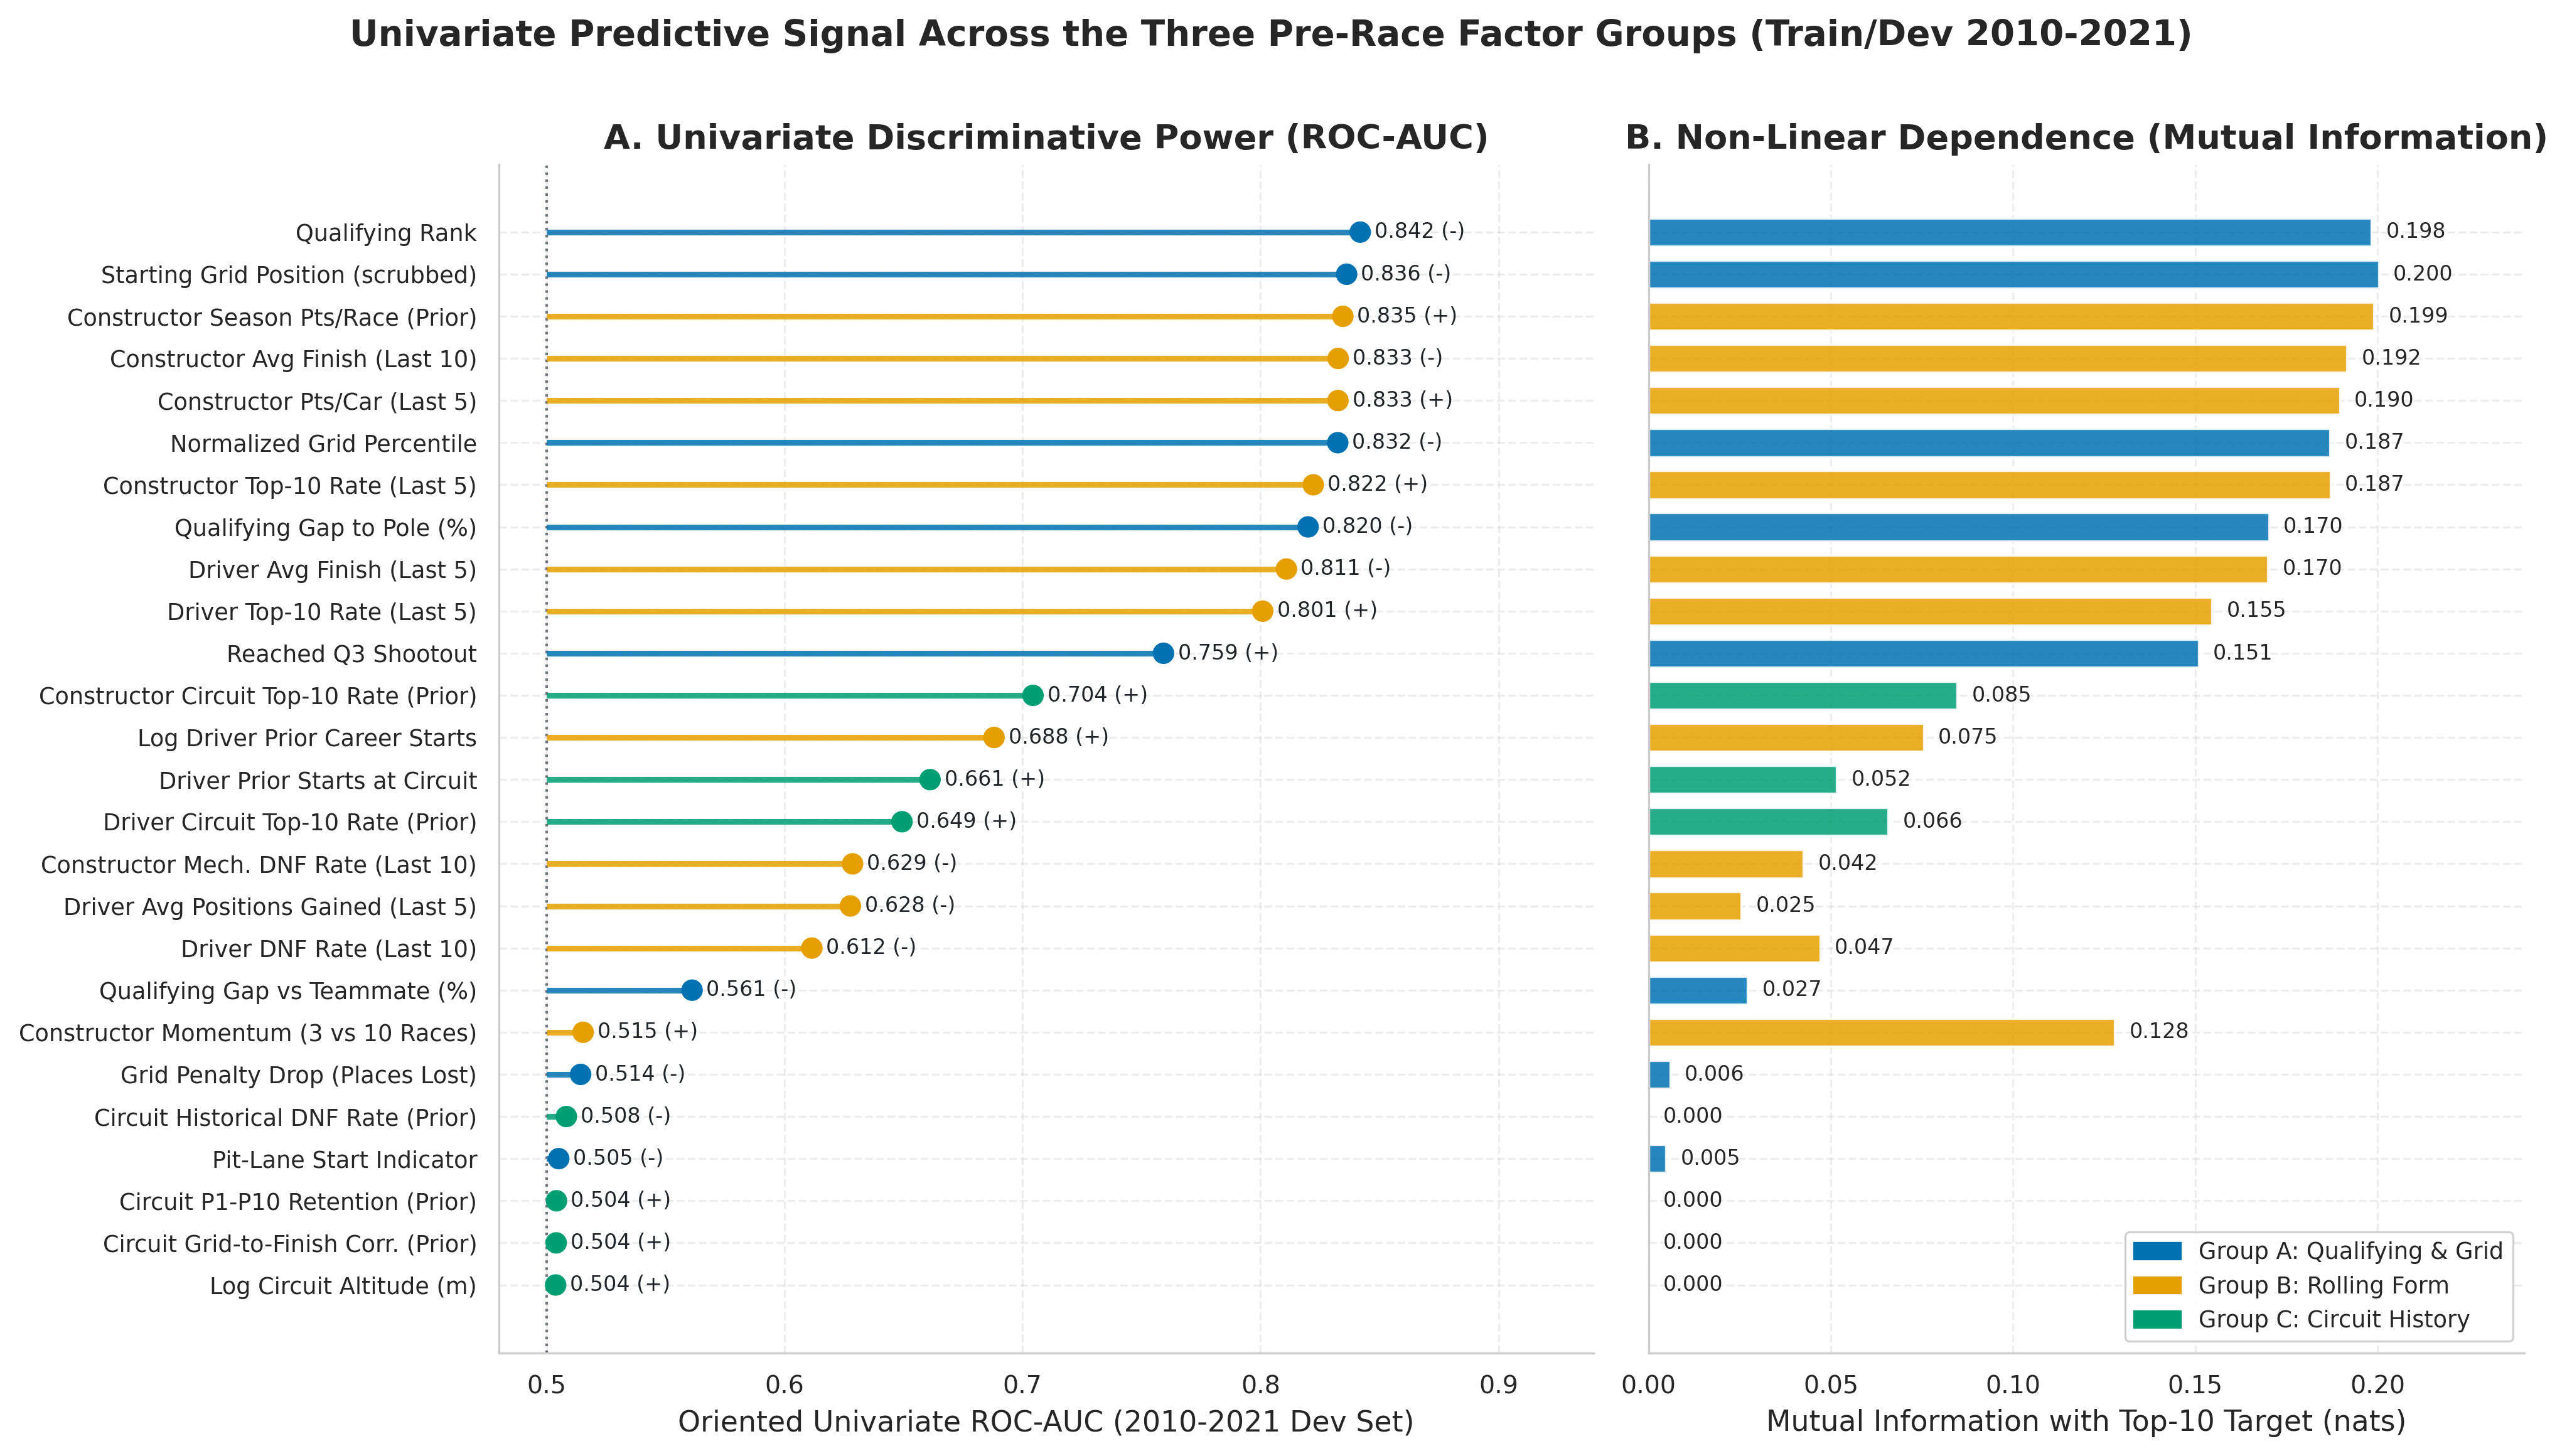

In [8]:
display(Image(filename=str(FIGURES_F1_DIR / "fig03_factor_group_signal_strength.png"), width=980))

### Visual Story 4: Grid $\times$ Constructor Form Interaction & Team Lineage Continuity
Panel A reveals the core geometric insight behind our hypothesis: **within the same starting grid band**, Top-10 probability shifts dramatically by constructor rolling form! For instance, starting **P16+ / Pit Lane** yields only a **2%** Top-10 rate for Q1 backmarkers, yet **66%** for Q5 top constructors; conversely, starting **P6–P10** yields **84%** for Q5 teams vs only **43%** for Q1 teams. This suggests a **tilted linear decision boundary** in `(Grid, Constructor Form)` space should substantially outperform the vertical `grid <= 10` cutoff!

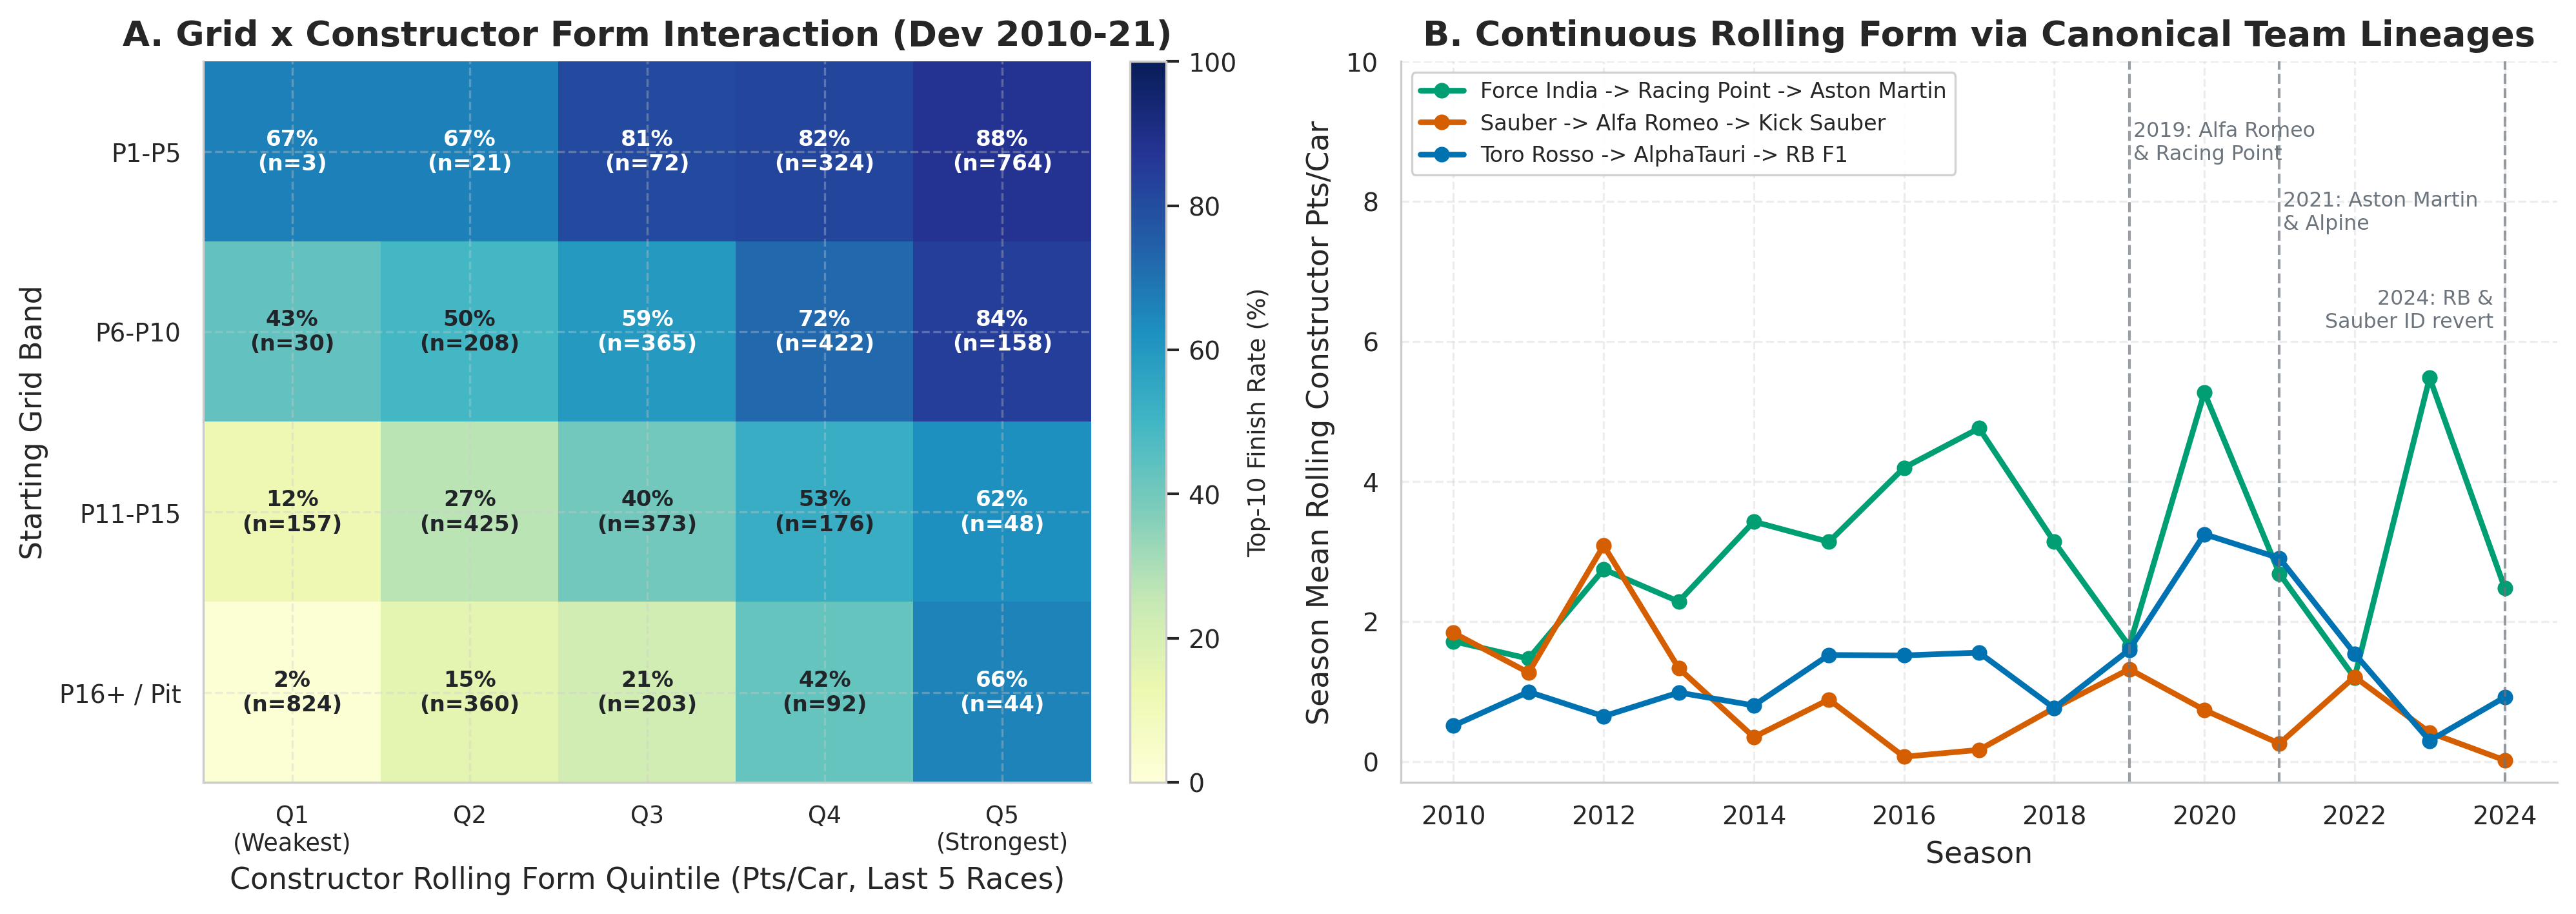

In [9]:
display(Image(filename=str(FIGURES_F1_DIR / "fig04_constructor_momentum_and_lineage.png"), width=980))

### Visual Story 5: Circuit Structural Regimes (Overtaking Difficulty vs Attrition)
Circuits span starkly distinct physical regimes: street/chaos circuits like **Baku** (25.5% DNF, Spearman $r=0.46$) and **Singapore** (23.0% DNF) disrupt grid order (`grid <= 10` drops to 72%–74%), while high-stability permanent circuits like **Shanghai**, **Montreal**, and **Barcelona** see `grid <= 10` exceed 80%.

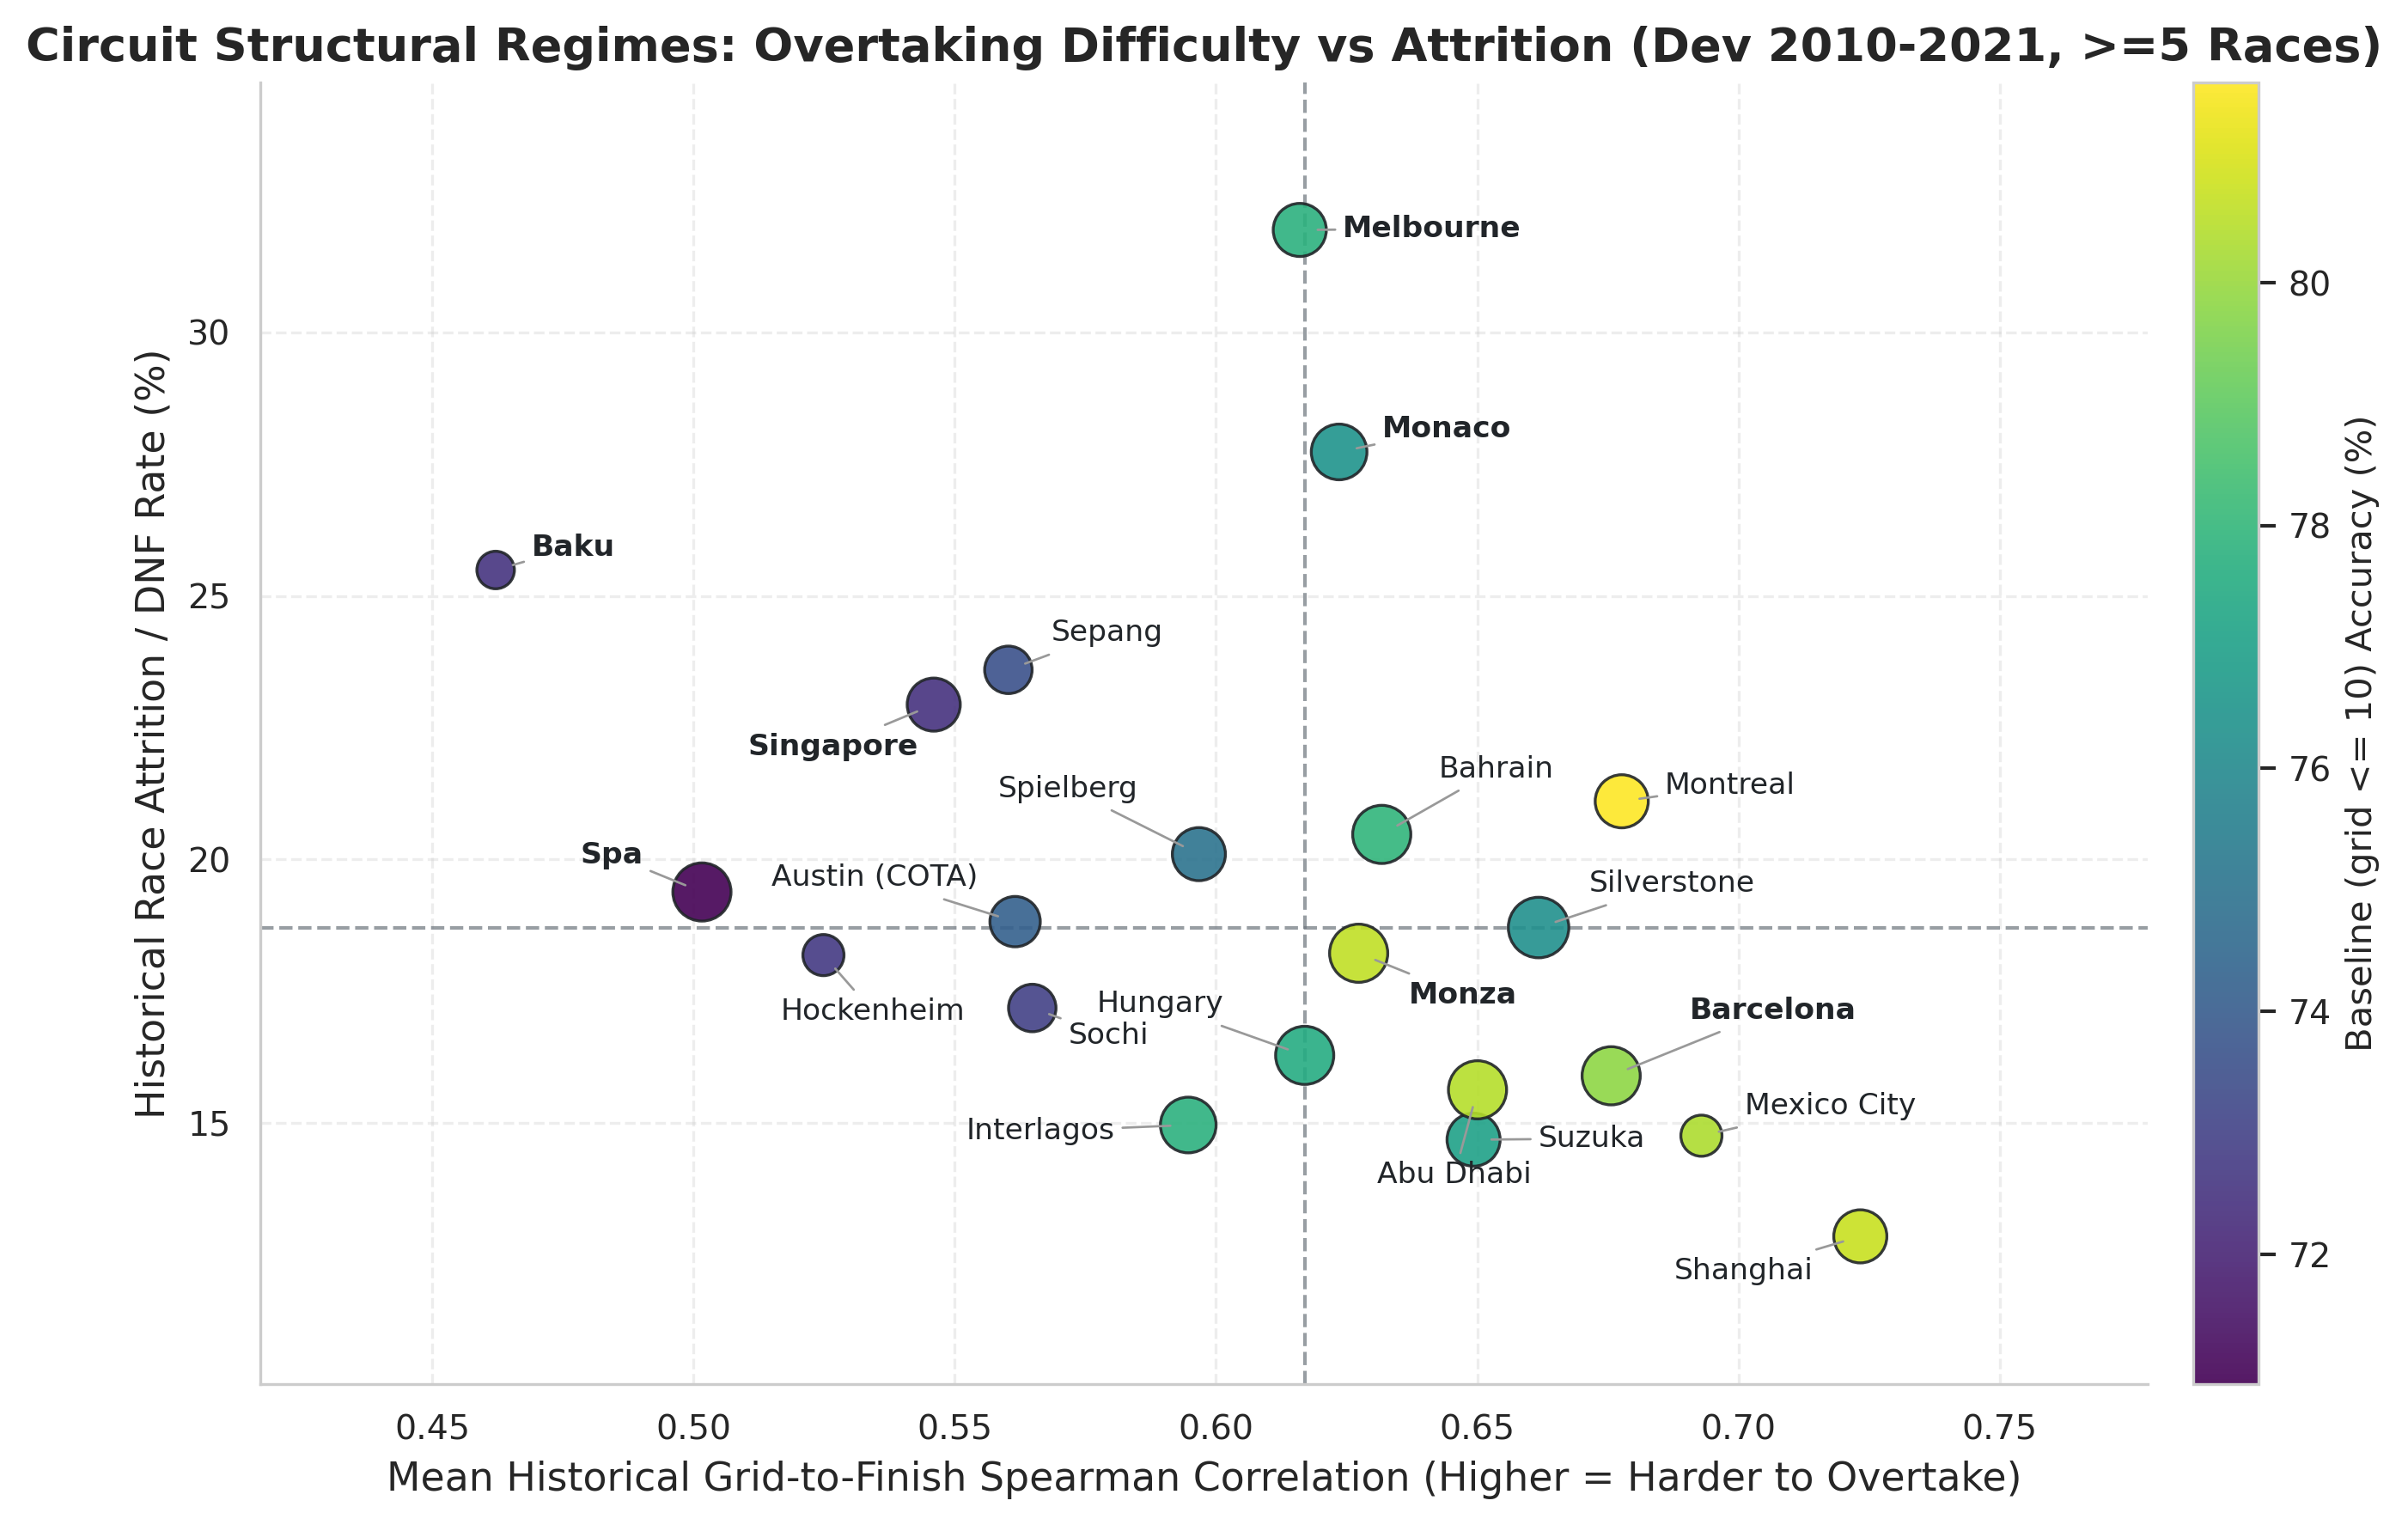

In [10]:
display(Image(filename=str(FIGURES_F1_DIR / "fig05_circuit_overtaking_vs_attrition.png"), width=860))

### Visual Story 6: Multicollinearity Diagnostics (Motivating L1/L2 Regularization)
Group-ordered Spearman correlations and Variance Inflation Factors reveal severe within-group collinearity (`grid_clean` VIF = 139.9, `qualy_pos` VIF = 104.1, `grid_pct` VIF = 53.5; constructor rolling form VIFs 13.8–22.2). This directly motivates **L2 (Ridge) and L1 (Lasso) Regularization** (Course Lecture 4) in Follow-up #2 to stabilize coefficient estimates and prevent variance inflation across temporal regime shifts.

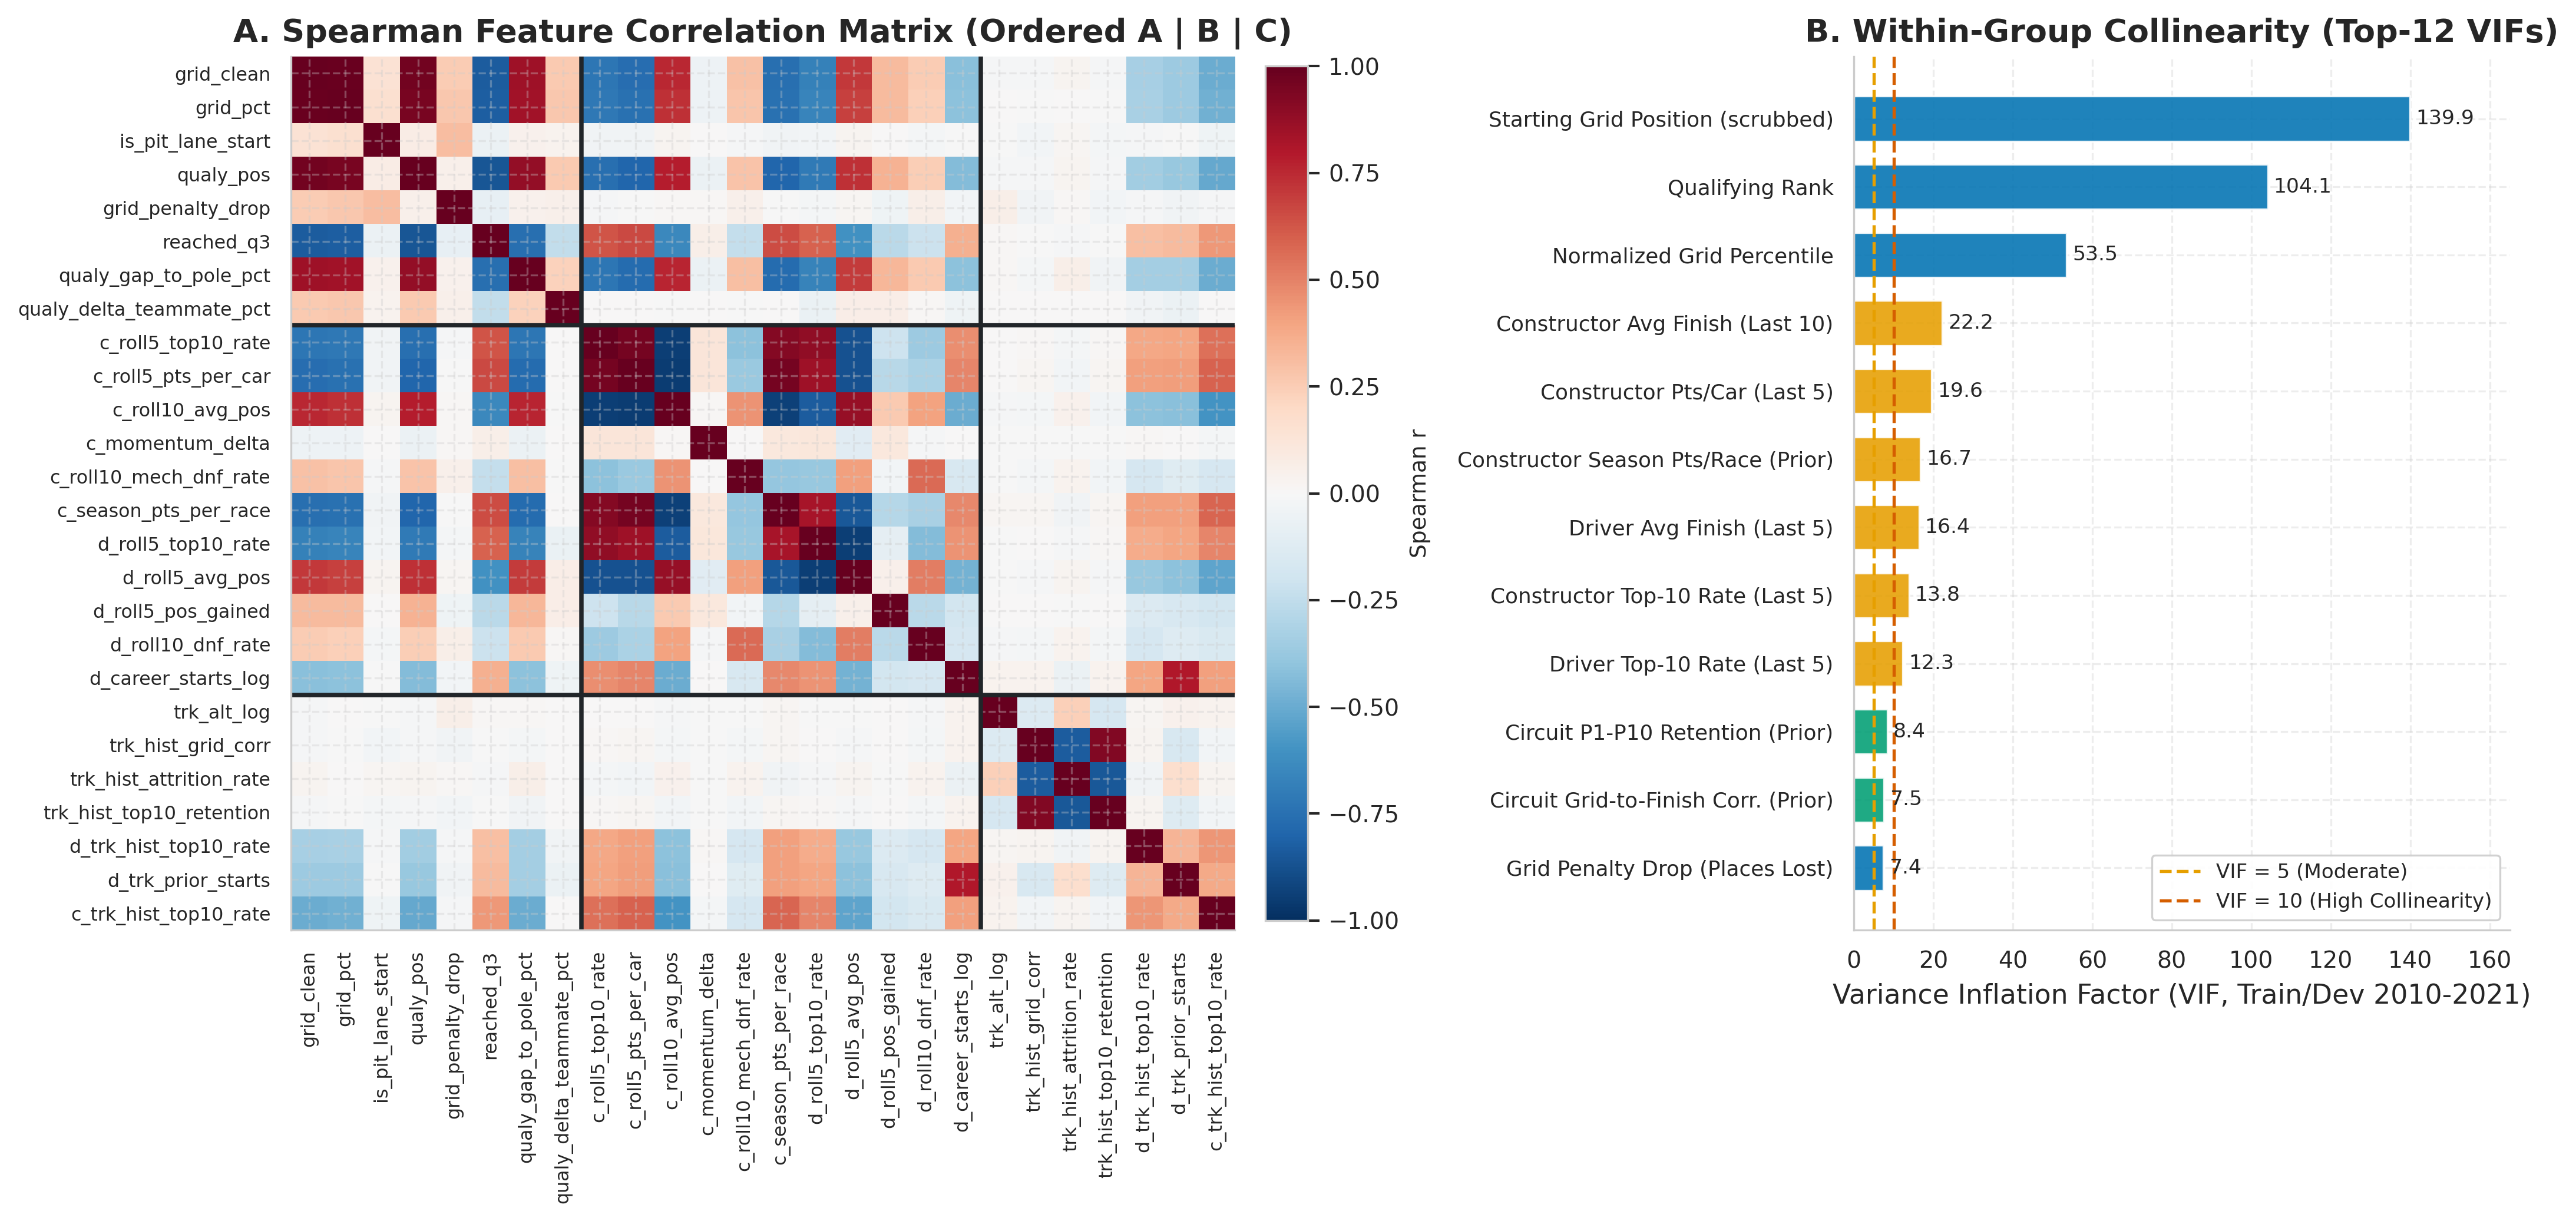

In [11]:
display(Image(filename=str(FIGURES_F1_DIR / "fig06_correlation_matrix_and_multicollinearity.png"), width=980))

---
## 7. Follow-up #1 Summary & Handoff to Follow-up #2 (Dec 11)

### Key Deliverables Completed for Follow-up #1
1. **Clean Relational Pipeline:** Loaded & audited all 14 Ergast CSV tables (`1950–2024`), restricted modeling to the balanced **2010–2024** Top-10 points era (`6,436` entries, `305` races, `47.39%` positive rate).
2. **Domain-Authentic Scrubbing:** Resolved `grid == 0` pit-lane starts (+0.89 pp baseline fix $\rightarrow$ `76.91%`), canonicalized 23 raw constructors into 13 continuous team lineages, and preserved clean within-fold missingness handling.
3. **Provably Leakage-Free Feature Matrix:** Engineered **26 pre-race features** across disjoint Groups **A (8)**, **B (11)**, and **C (7)** and passed all automated adversarial future-mutation & same-race-mutation tests (`max_abs_diff = 0.0`).
4. **Processed Artifact Handoff:** Saved `data/processed/f1_modeling_2010_2024.parquet` (and `.csv`) plus `feature_metadata.json` for direct consumption by **Delivery 2 (`notebooks/02_followup2_model_interpret.ipynb`)**.

### Modeling Roadmap for Follow-up #2
* Benchmark **9 ML algorithms** from the course curriculum (L2/L1 Logistic Regression, Linear SVM, Gaussian Naive Bayes, k-NN, RBF SVM, Decision Tree, Random Forest, Gradient Boosting) against **3 baselines** (`Majority`, `grid <= 10`, `Grid-Only Logistic`) using **5-fold expanding-window seasonal CV (2017–2021)** and **held-out Ground-Effect Test seasons (2022–2024)**.
* Execute the centerpiece **$2^3 - 1 = 7$-subset ablation matrix** across 5 model families with exact **Shapley group attribution** ($\phi_A, \phi_B, \phi_C$).
* Conduct "what-if" studies (L1/L2 regularization paths, rolling window sensitivity, lineage canonicalization impact, operating-threshold tuning) and **post-hoc irreducible DNF error decomposition**.